# 03 - LLM Results and Model Comparison

ADS-509 Final Project (Group 2)

This notebook scores the LLM classifier (`llm_extraction.py`) and compares it with the Sentence-BERT + logistic regression models from notebook 02. All four models are scored on the same 193 test reports from notebook 02's group split (`data/test_group_split.csv`).

**Models compared**

| Model | How it works | Training data used |
|---|---|---|
| LLM v1 | Claude Haiku via API, plain-language label definitions | None (zero-shot) |
| LLM v2 | Same model, label definitions aligned with how MAUDE event types are assigned | None (zero-shot) |
| SBERT + LogReg | Sentence embeddings + logistic regression (notebook 02) | 758 labeled reports |
| SBERT + Balanced LogReg | Same, with balanced class weights | 758 labeled reports |

**Sections**
1. Load and merge predictions
2. Main results on all 193 test reports
3. Robustness check: one row per unique narrative (128)
4. Robustness check: v2 without reports that shaped its prompt
5. Confusion matrices and per-class recall
6. Error review
7. What the LLM extracts beyond the label (failure modes and harm flag)

*AI assistance disclosure: this notebook was drafted with Claude (Anthropic) and reviewed, run, and checked by Kamran Shirazi.*

In [1]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             recall_score)

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

LABELS = ["Malfunction", "Injury", "Death"]   # order used in every table/chart
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Load and merge predictions

Every file is keyed by `report_id`, so we join them into one table with the FDA label and each model's prediction.

In [2]:
# Ground truth: notebook 02's group-split test set
test = pd.read_csv("data/test_group_split.csv", dtype={"report_id": str})

# LLM predictions (written by llm_extraction.py --test-file data/test_group_split.csv)
llm_v1 = pd.read_csv("results/llm_v1_testgroup.csv", dtype={"report_id": str})
llm_v2 = pd.read_csv("results/llm_v2_testgroup.csv", dtype={"report_id": str})

# SBERT predictions from notebook 02
bert = pd.read_csv("results/bert_logreg_predictions.csv", dtype={"report_id": str})

df = (test.rename(columns={"event_type": "fda_label"})
          .merge(llm_v1[["report_id", "event_type", "failure_mode", "patient_harm"]]
                 .rename(columns={"event_type": "LLM v1",
                                  "failure_mode": "failure_mode_v1",
                                  "patient_harm": "harm_v1"}),
                 on="report_id", how="left")
          .merge(llm_v2[["report_id", "event_type", "failure_mode", "patient_harm"]]
                 .rename(columns={"event_type": "LLM v2",
                                  "failure_mode": "failure_mode_v2",
                                  "patient_harm": "harm_v2"}),
                 on="report_id", how="left")
          .merge(bert[["report_id", "predicted_standard", "predicted_balanced"]]
                 .rename(columns={"predicted_standard": "SBERT + LogReg",
                                  "predicted_balanced": "SBERT + Balanced LogReg"}),
                 on="report_id", how="left"))

MODELS = ["LLM v1", "LLM v2", "SBERT + LogReg", "SBERT + Balanced LogReg"]

# Sanity checks: every test report has a prediction from every model
assert len(df) == len(test) == 193
assert df[MODELS].notna().all().all(), "a model is missing predictions"
print(f"{len(df)} test reports, all four models present")
print(df["fda_label"].value_counts().reindex(LABELS))

193 test reports, all four models present
fda_label
Malfunction    101
Injury          75
Death           17
Name: count, dtype: int64


## 2. Main results on all 193 test reports

In [3]:
def score_models(data: pd.DataFrame) -> pd.DataFrame:
    """Accuracy, macro F1, error count, and per-class recall for each model."""
    rows = []
    for m in MODELS:
        y_true, y_pred = data["fda_label"], data[m]
        recalls = recall_score(y_true, y_pred, labels=LABELS, average=None,
                               zero_division=0)
        rows.append({
            "model": m,
            "n": len(data),
            "accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro"),
            "errors": int((y_true != y_pred).sum()),
            **{f"{lab.lower()}_recall": r for lab, r in zip(LABELS, recalls)},
        })
    return pd.DataFrame(rows).set_index("model")

full_scores = score_models(df)
full_scores.round(3)

,n,accuracy,macro_f1,errors,malfunction_recall,injury_recall,death_recall
model,,,,,,,
LLM v1,193,0.943,0.940,11,1.00,0.880,0.882
LLM v2,193,0.984,0.981,3,1.00,0.973,0.941
SBERT + LogReg,193,0.974,0.954,5,1.00,0.973,0.824
SBERT + Balanced LogReg,193,0.974,0.964,5,0.98,0.987,0.882


## 3. Robustness check: one row per unique narrative

GroupShuffleSplit keeps identical narratives on the same side of the split, so there is no train/test leakage. But inside the test set, some narratives repeat many times (one appears 33 times). These are mostly short, easy Malfunction reports, so each correct answer gets counted over and over. Here we keep one row per unique narrative and rescore. No model is rerun: the predictions are the same, only the counting changes.

In [4]:
dup_counts = df["narrative"].value_counts()
print(f"Unique narratives: {df['narrative'].nunique()} of {len(df)} reports")
print(f"Largest repeat counts: {dup_counts.head(5).tolist()}")

# All repeats of a narrative share one FDA label, so keeping the first is safe
assert (df.groupby("narrative")["fda_label"].nunique() == 1).all()

dedup = df.drop_duplicates(subset="narrative", keep="first")
print(dedup["fda_label"].value_counts().reindex(LABELS))

dedup_scores = score_models(dedup)
dedup_scores.round(3)

Unique narratives: 128 of 193 reports
Largest repeat counts: [33, 18, 5, 5, 4]
fda_label
Malfunction    37
Injury         74
Death          17
Name: count, dtype: int64


,n,accuracy,macro_f1,errors,malfunction_recall,injury_recall,death_recall
model,,,,,,,
LLM v1,128,0.914,0.916,11,1.000,0.878,0.882
LLM v2,128,0.977,0.972,3,1.000,0.973,0.941
SBERT + LogReg,128,0.961,0.946,5,1.000,0.973,0.824
SBERT + Balanced LogReg,128,0.961,0.952,5,0.946,0.986,0.882


In [5]:
# Side-by-side summary for the slides
summary = pd.concat(
    {"All 193 reports": full_scores[["accuracy", "macro_f1", "errors"]],
     "128 unique narratives": dedup_scores[["accuracy", "macro_f1", "errors"]]},
    axis=1)
summary.round(3)

All 193 reports                 128 unique narratives  \
                               accuracy macro_f1 errors              accuracy   
model                                                                           
LLM v1                            0.943    0.940     11                 0.914   
LLM v2                            0.984    0.981      3                 0.977   
SBERT + LogReg                    0.974    0.954      5                 0.961   
SBERT + Balanced LogReg           0.974    0.964      5                 0.961   

                                         
                        macro_f1 errors  
model                                    
LLM v1                     0.916     11  
LLM v2                     0.972      3  
SBERT + LogReg             0.946      5  
SBERT + Balanced LogReg    0.952      5

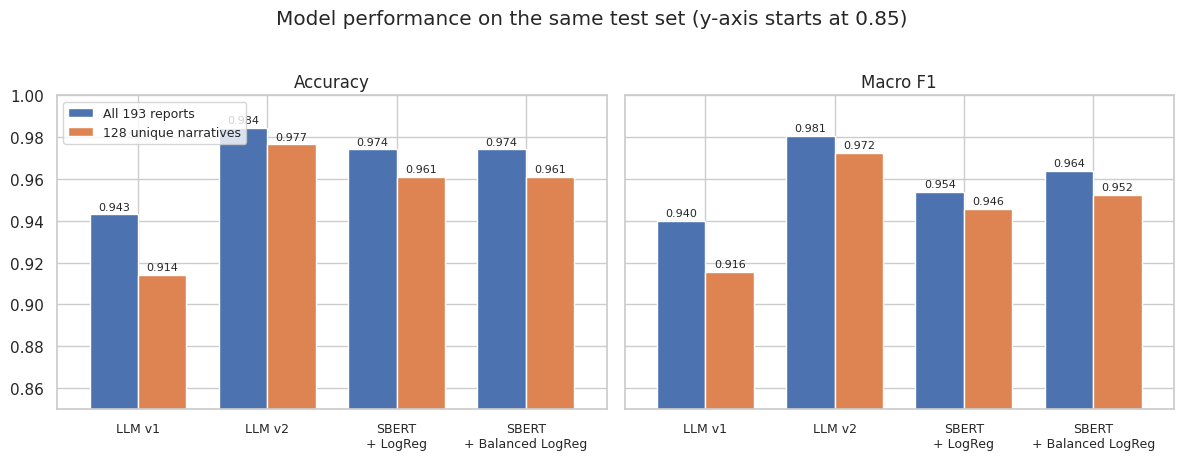

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
palette = {"All 193 reports": "#4C72B0", "128 unique narratives": "#DD8452"}

for ax, metric, title in zip(axes, ["accuracy", "macro_f1"], ["Accuracy", "Macro F1"]):
    plot_df = pd.DataFrame({"All 193 reports": full_scores[metric],
                            "128 unique narratives": dedup_scores[metric]})
    plot_df.plot.bar(ax=ax, color=palette, width=0.75, rot=0, legend=(metric == "accuracy"))
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylim(0.85, 1.0)
    ax.set_xticklabels([m.replace(" + ", "\n+ ") for m in plot_df.index], fontsize=9)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)

axes[0].legend(loc="upper left", fontsize=9)
fig.suptitle("Model performance on the same test set (y-axis starts at 0.85)", y=1.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Robustness check: v2 without reports that shaped its prompt

The v2 prompt rules were written after reviewing v1's errors on the *original* test split (before the group split). Three of those reports ended up in the new test set, so v2 had indirect exposure to them. Here we drop those three and rescore every model on the remaining 190 for a fair comparison.

In [7]:
v1_old_errors = pd.read_csv("results/llm_errors_v1.csv", dtype={"report_id": str})
seen_ids = set(v1_old_errors["report_id"]) & set(df["report_id"])
print(f"Reports in the test set that informed the v2 prompt: {len(seen_ids)}")

unseen_scores = score_models(df[~df["report_id"].isin(seen_ids)])
unseen_scores[["n", "accuracy", "macro_f1", "errors"]].round(3)

Reports in the test set that informed the v2 prompt: 3


,n,accuracy,macro_f1,errors
model,,,,
LLM v1,190,0.958,0.960,8
LLM v2,190,0.984,0.980,3
SBERT + LogReg,190,0.974,0.952,5
SBERT + Balanced LogReg,190,0.974,0.962,5


## 5. Confusion matrices and per-class recall

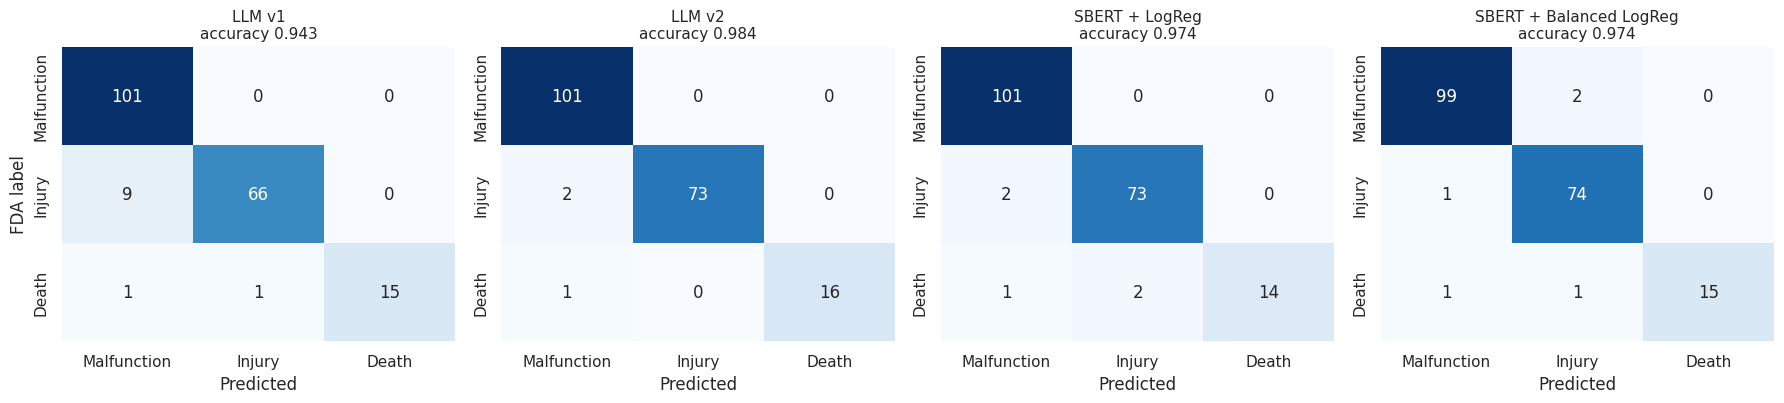

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, m in zip(axes, MODELS):
    cm = confusion_matrix(df["fda_label"], df[m], labels=LABELS)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS, annot_kws={"size": 12})
    ax.set_title(f"{m}\naccuracy {full_scores.loc[m, 'accuracy']:.3f}", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("FDA label" if m == MODELS[0] else "")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

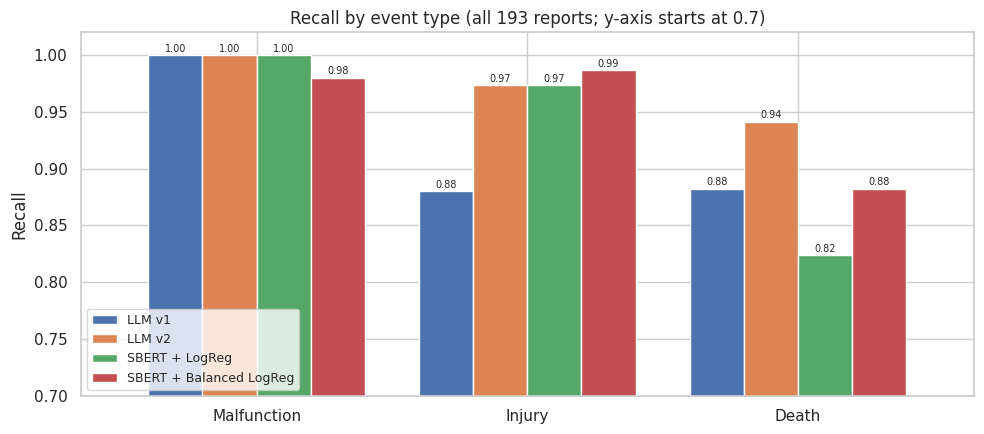

,Malfunction,Injury,Death
model,,,
LLM v1,1.00,0.880,0.882
LLM v2,1.00,0.973,0.941
SBERT + LogReg,1.00,0.973,0.824
SBERT + Balanced LogReg,0.98,0.987,0.882


In [9]:
recall_cols = [f"{lab.lower()}_recall" for lab in LABELS]
recall_df = full_scores[recall_cols].rename(columns=dict(zip(recall_cols, LABELS)))

ax = recall_df.T.plot.bar(figsize=(10, 4.5), rot=0, width=0.8)
ax.set_ylim(0.7, 1.02)
ax.set_ylabel("Recall")
ax.set_title("Recall by event type (all 193 reports; y-axis starts at 0.7)")
ax.legend(fontsize=9, loc="lower left")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=1)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/recall_by_class.png", dpi=200, bbox_inches="tight")
plt.show()

recall_df.round(3)

## 6. Error review

Which reports does each model get wrong, and in which direction? An error that predicts a *less* severe label than FDA (for example Injury called Malfunction) is the riskier kind for safety surveillance, because it would hide a harmful event.

In [10]:
severity = {"Malfunction": 0, "Injury": 1, "Death": 2}

direction = pd.DataFrame({
    m: {"under (less severe than FDA)":
            int((df[m].map(severity) < df["fda_label"].map(severity)).sum()),
        "over (more severe than FDA)":
            int((df[m].map(severity) > df["fda_label"].map(severity)).sum())}
    for m in MODELS}).T
direction

,under (less severe than FDA),over (more severe than FDA)
LLM v1,11,0
LLM v2,3,0
SBERT + LogReg,5,0
SBERT + Balanced LogReg,3,2


In [11]:
# Reports each model got wrong, as a 0/1 grid
wrong = pd.DataFrame({m: (df[m] != df["fda_label"]).astype(int) for m in MODELS})
any_wrong = df[wrong.any(axis=1)][["report_id", "fda_label"] + MODELS + ["narrative"]]
print(f"{len(any_wrong)} reports missed by at least one model; "
      f"{int(wrong.all(axis=1).sum())} missed by all four")
any_wrong.assign(narrative=any_wrong["narrative"].str[:250])

15 reports missed by at least one model; 1 missed by all four


,report_id,fda_label,LLM v1,LLM v2,SBERT + LogReg,SBERT + Balanced LogReg,narrative
58,3013756811-2020-42907,Malfunction,Malfunction,Malfunction,Malfunction,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 300 MG/DL, AND THE ME..."
59,3013756811-2020-42918,Malfunction,Malfunction,Malfunction,Malfunction,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 300 MG/DL, AND THE ME..."
102,3013756811-2020-40377,Injury,Malfunction,Injury,Injury,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS BELOW 40 MG/DL, AND T..."
118,MW5094429,Injury,Malfunction,Injury,Injury,Injury,"MY DAUGHTER IS A (B)(6) YEAR OLD TYPE 1 DIABETIC AND USES THE DEXCOM G6 CONTINUOUS GLUCOSE MONITOR. THE DEXCOM SENSOR IS APPLIED VIA A DEVICE WHERE YOU PUSH A BUTTON AND THE NEEDLE GOES IN, THEN O..."
135,3013756811-2020-53870,Injury,Malfunction,Injury,Injury,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS 227 MG/DL, AND THE ME..."
149,3004753838-2020-056981,Injury,Malfunction,Injury,Injury,Injury,"WHEN EMS ARRIVED, THEY PERFORMED A FINGER STICK BG AND THE VALUE WAS 285 MG/DL."
152,3013756811-2020-59486,Injury,Malfunction,Malfunction,Malfunction,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS BELOW 40 MG/DL, AND T..."
166,3013756811-2020-67080,Injury,Malfunction,Injury,Malfunction,Malfunction,IT WAS REPORTED THAT THE TRANSMITTER LOST CONNECTION WITH THE PUMP FOR GREATER THAN 1 HOUR. TRANSMITTER WAS REPLACED TO RESOLVE THE ISSUE. THE CUSTOMER¿S BLOOD GLUCOSE LEVEL WAS 51 MG/DL AND WAS A...
169,MW5095512,Injury,Malfunction,Injury,Injury,Injury,CALLER REPORTS SHE RECENTLY GOT DIAGNOSED WITH TYPE 1 DIABETES AND HER PHYSICIAN RECOMMENDED THE DEXCOM G6. SHE LOVED THE PRODUCT AND DID NOT HAVE ANY ISSUES UNTIL RECENTLY WHEN SHE NOTICED THE SE...
170,3013756811-2020-71978,Injury,Malfunction,Malfunction,Injury,Injury,"IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS ""LOW"", AND THE METER ..."


### LLM v2's remaining errors

Reading the full narratives helps tell model mistakes apart from label noise (reports where the narrative doesn't clearly support FDA's label).

In [12]:
v2_errors = df[df["LLM v2"] != df["fda_label"]]
for _, r in v2_errors.iterrows():
    print(f"{r['report_id']} | FDA: {r['fda_label']} | v2: {r['LLM v2']} "
          f"| failure mode: {r['failure_mode_v2']}")
    print(r["narrative"][:1200])
    print("-" * 100)

3013756811-2020-59486 | FDA: Injury | v2: Malfunction | failure mode: CGM reading inaccurate compared to meter reading
IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS BELOW 40 MG/DL, AND THE METER BG READING WAS 135 MG/DL. REPORTEDLY, THE CUSTOMER HAD A LOW BG OF BELOW 40 BUT DECLINED TROUBLESHOOTING WITH TANDEM TECHNICAL SUPPORT. NO ADDITIONAL PATIENT OR EVENT INFORMATION WAS AVAILABLE. A ROOT CAUSE COULD NOT BE DETERMINED. A REPLACEMENT SENSOR WAS SENT TO THE CUSTOMER.
----------------------------------------------------------------------------------------------------
3013756811-2020-71978 | FDA: Injury | v2: Malfunction | failure mode: Inaccurate CGM glucose reading versus meter
IT WAS REPORTED THAT THERE WAS AN INACCURACY BETWEEN THE CONTINUOUS GLUCOSE MONITOR (CGM) READING AND THE BLOOD GLUCOSE (BG) METER READING. REPORTEDLY, THE CGM BG READING WAS "LOW", 

## 7. What the LLM extracts beyond the label

Besides the event type, each LLM call returns a short free-text **failure mode** and a **patient harm** flag. SBERT can only produce the label. Below we group v2's failure-mode phrases into broad categories with simple keyword rules to show what kinds of device problems appear in the test set.

In [13]:
# Simple keyword rules, checked in order (first match wins)
CATEGORY_RULES = [
    ("Skin / adhesive reaction", ["skin", "adhesive", "rash", "allerg", "blister", "hives", "itch", "burn"]),
    ("Needle / applicator / pain", ["needle", "applicator", "inserter", "insertion", "wire", "bleed", "pain"]),
    ("Connection / signal loss",  ["signal", "connection", "pairing", "connect"]),
    ("Transmitter failure",       ["transmitter", "voltage", "battery"]),
    ("App / display problem",     ["app", "crash", "login", "display", "frozen"]),
    ("Missed or failed alert",    ["alert", "alarm"]),
    ("Inaccurate reading",        ["inaccura", "falsely", "false", "reading", "low glucose", "high glucose"]),
    ("Sensor error / expiration", ["sensor", "expir"]),
]

def categorize(phrase: str) -> str:
    """Map an LLM failure-mode phrase to a broad category.

    Keywords match at the start of a word, so "rash" does not match "crash".
    """
    text = str(phrase).lower()
    if text in ("unknown", "nan", ""):
        return "Not described"
    for category, keywords in CATEGORY_RULES:
        if any(re.search(r"\b" + k, text) for k in keywords):
            return category
    return "Other"

df["failure_category"] = df["failure_mode_v2"].apply(categorize)

# Spot check: a few phrases per category so the rules can be verified by eye
(df.groupby("failure_category")["failure_mode_v2"]
   .agg(lambda s: list(s.drop_duplicates()[:3])))

failure_category
App / display problem                                                [Receiver display frozen, Unexpected login prompt during mobile app session, App crash alert; cause not determined]
Connection / signal loss                                                      [Signal loss over one hour, Pairing failure due to signal loss, Loss of connection between device and app]
Inaccurate reading            [CGM reading inaccurate compared to blood glucose meter, Inaccurate CGM reading compared to blood glucose meter, CGM reading inaccurate compared to meter]
Missed or failed alert                               [Failed to alert on low glucose, Missed urgent low alerts; alert not heard, Sensor error and sensor failure with missed low alerts]
Needle / applicator / pain                                      [Detached sensor wire, Applicator failed to release sensor, stuck on body, Sensor causing constant sharp abdominal pain]
Not described                                             

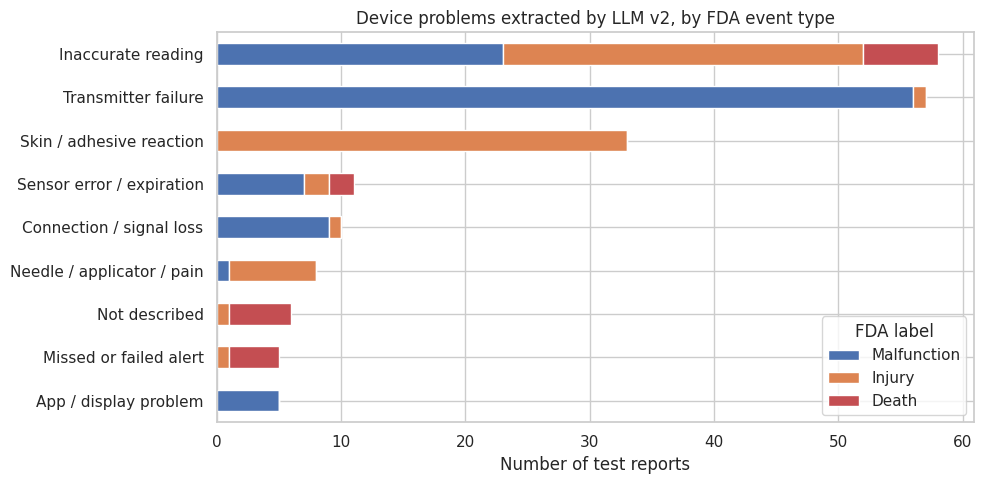

fda_label,Malfunction,Injury,Death
failure_category,,,
Inaccurate reading,23,29,6
Transmitter failure,56,1,0
Skin / adhesive reaction,0,33,0
Sensor error / expiration,7,2,2
Connection / signal loss,9,1,0
Needle / applicator / pain,1,7,0
Not described,0,1,5
Missed or failed alert,0,1,4
App / display problem,5,0,0


In [14]:
cat_counts = pd.crosstab(df["failure_category"], df["fda_label"])[LABELS]
cat_counts = cat_counts.loc[cat_counts.sum(axis=1).sort_values().index]

ax = cat_counts.plot.barh(stacked=True, figsize=(10, 5),
                          color=["#4C72B0", "#DD8452", "#C44E52"])
ax.set_xlabel("Number of test reports")
ax.set_ylabel("")
ax.set_title("Device problems extracted by LLM v2, by FDA event type")
ax.legend(title="FDA label")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/failure_modes.png", dpi=200, bbox_inches="tight")
plt.show()

cat_counts.iloc[::-1]

In [15]:
# Does the harm flag agree with the event type? (v2 prompt asks for harm = Yes
# whenever the event type is Injury or Death)
harm_check = pd.crosstab(df["LLM v2"], df["harm_v2"]).reindex(LABELS)
harm_check

harm_v2,No,Yes
LLM v2,,
Malfunction,104,0
Injury,0,73
Death,0,16


## Save results

In [16]:
os.makedirs("results", exist_ok=True)
comparison = pd.concat(
    {"all_193": full_scores,
     "unique_128": dedup_scores,
     "excl_prompt_dev_190": unseen_scores},
    names=["eval_set", "model"]).round(4)
comparison.to_csv("results/model_comparison.csv")
comparison

n  accuracy  macro_f1  errors  \
eval_set            model                                                      
all_193             LLM v1                   193    0.9430    0.9400      11   
                    LLM v2                   193    0.9845    0.9805       3   
                    SBERT + LogReg           193    0.9741    0.9540       5   
                    SBERT + Balanced LogReg  193    0.9741    0.9638       5   
unique_128          LLM v1                   128    0.9141    0.9157      11   
                    LLM v2                   128    0.9766    0.9723       3   
                    SBERT + LogReg           128    0.9609    0.9457       5   
                    SBERT + Balanced LogReg  128    0.9609    0.9523       5   
excl_prompt_dev_190 LLM v1                   190    0.9579    0.9598       8   
                    LLM v2                   190    0.9842    0.9797       3   
                    SBERT + LogReg           190    0.9737    0.9515       5   
                    SBERT + Balanced LogReg  190    0.9737    0.9622       5   

                                             malfunction_recall  \
eval_set            model                                         
all_193             LLM v1                               1.0000   
                    LLM v2                               1.0000   
                    SBERT + LogReg                       1.0000   
                    SBERT + Balanced LogReg              0.9802   
unique_128          LLM v1                               1.0000   
                    LLM v2                               1.0000   
                    SBERT + LogReg                       1.0000   
                    SBERT + Balanced LogReg              0.9459   
excl_prompt_dev_190 LLM v1                               1.0000   
                    LLM v2                               1.0000   
                    SBERT + LogReg                       1.0000   
                    SBERT + Balanced LogReg              0.9802   

                                             injury_recall  death_recall  
eval_set            model                                                 
all_193             LLM v1                          0.8800        0.8824  
                    LLM v2                          0.9733        0.9412  
                    SBERT + LogReg                  0.9733        0.8235  
                    SBERT + Balanced LogReg         0.9867        0.8824  
unique_128          LLM v1                          0.8784        0.8824  
                    LLM v2                          0.9730        0.9412  
                    SBERT + LogReg                  0.9730        0.8235  
                    SBERT + Balanced LogReg         0.9865        0.8824  
excl_prompt_dev_190 LLM v1                          0.9041        0.9375  
                    LLM v2                          0.9726        0.9375  
                    SBERT + LogReg                  0.9726        0.8125  
                    SBERT + Balanced LogReg         0.9863        0.8750

## Summary

**LLM v2 is the most accurate model, with no training data.** On all 193 test reports it scores 0.984 accuracy and 0.981 macro F1 with 3 errors. The SBERT models, trained on 758 labeled reports, both score 0.974 accuracy with 5 errors. LLM v1 (plain-language definitions) scores 0.943 with 11 errors, so most of the LLM's gain came from writing label definitions that match how MAUDE event types are actually assigned.

**The ranking holds under both robustness checks.**
- One row per unique narrative (128): every model drops 1 to 3 points because the repeated easy Malfunction reports are no longer counted many times. v2 still leads (0.977 vs 0.961 for SBERT).
- Excluding the 3 test reports that informed v2's prompt (190 left): v2 still makes 3 errors and scores 0.984. Those 3 reports were v1 errors that v2 fixed, so removing them only helps v1.

**Death is where the models differ most.** v2 catches 16 of 17 deaths, the balanced SBERT model 15, and standard SBERT 14. With only 17 deaths, each one is worth about 6 points of recall.

**Error direction matters for safety surveillance.** Every LLM error predicts a less severe label than FDA (it under-calls). The balanced SBERT model trades some of that for 2 over-calls, where a Malfunction is flagged as Injury. For triage, an over-call costs a reviewer's time, while an under-call can hide a harmful event.

**v2's remaining errors look partly like label noise.** Two are inaccurate-reading reports with no treatment or symptoms described that FDA labeled Injury. The third is labeled Death, but the narrative describes alerts working as expected and a sensor session that ended normally.

**The LLM returns more than a label.** Each call also extracts a failure mode and a harm flag. Grouping the failure modes shows transmitter failures are almost all Malfunctions, skin and adhesive reactions are almost all Injuries, and missed alerts and undescribed problems concentrate in Death reports. The harm flag agrees with the predicted event type on all 193 reports.

**Limitations**
- Small test set (193 reports, 17 Deaths), so one error moves Death recall by about 6 points.
- FDA labels reflect manufacturer reporting practice and contain some noise; a few "errors" may be label problems.
- v2's rules were written after looking at v1's errors on an earlier split, so it was tuned with some knowledge of this data.
- The LLM was run once per report and results were cached, so run-to-run variability is not measured.
- Failure-mode categories come from simple keyword rules and were spot-checked, not formally validated.